In [ ]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset
from sklearn.datasets import fetch_california_housing

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Model evaluation
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

In [ ]:
# Load California Housing dataset
housing = fetch_california_housing(as_frame=True)

# Convert dataset into a DataFrame
df = housing.frame

# Display first five records
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check column information
df.info()

# Check statistical summary
df.describe()

Dataset shape: (20640, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [ ]:
# Check missing values in each column
print(df.isnull().sum())

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [ ]:
# Count duplicate records
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


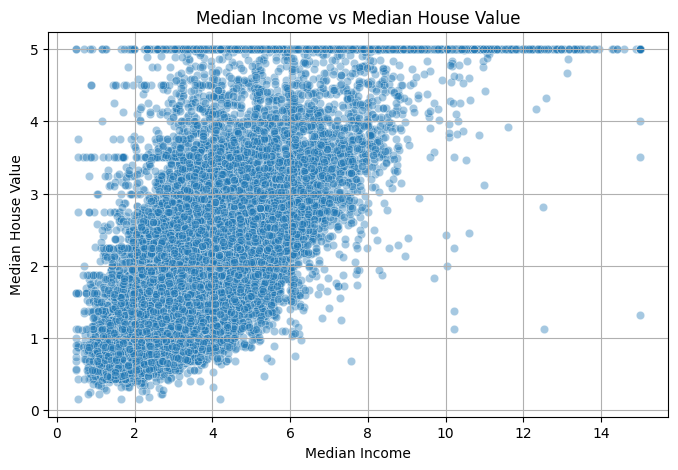

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="MedInc",
    y="MedHouseVal",
    alpha=0.4
)
plt.grid()
plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")

plt.show()

In [ ]:
# Independent variables (features)
X = df.drop("MedHouseVal", axis=1)

# Dependent variable (target)
y = df["MedHouseVal"]


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


In [ ]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16512, 8)
Testing data: (4128, 8)


In [ ]:
# Create a Linear Regression model
model = LinearRegression()

In [ ]:
# Train the model using training data
model.fit(X_train, y_train)


LinearRegression()

In [ ]:
# Predict house prices using testing data
y_pred = model.predict(X_test)

In [ ]:
comparison = pd.DataFrame({
    "Actual Price": y_test,
    "Predicted Price": y_pred
})

comparison.head(10)

,Actual Price,Predicted Price
20046,0.47700,0.719123
3024,0.45800,1.764017
15663,5.00001,2.709659
20484,2.18600,2.838926
9814,2.78000,2.604657
13311,1.58700,2.011754
7113,1.98200,2.645500
7668,1.57500,2.168755
18246,3.40000,2.740746
5723,4.46600,3.915615


In [ ]:
# Predict using training data
y_train_pred = model.predict(X_train)

# Calculate training R-squared
train_r2 = r2_score(y_train, y_train_pred)

print("Training R-squared:", train_r2)

Training R-squared: 0.6125511913966952


In [ ]:
r2 = r2_score(y_test,y_pred)
print("R-squared:", r2)

R-squared: 0.5757877060324512


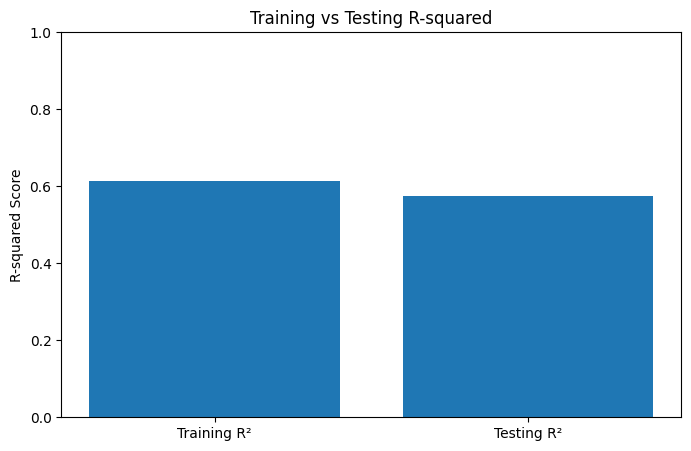

In [ ]:
# visualizing the models to check the model performence
scores = {
    "Training R²": train_r2,
    "Testing R²": r2
}

plt.figure(figsize=(8, 5))

plt.bar(scores.keys(), scores.values())

plt.title("Training vs Testing R-squared")
plt.ylabel("R-squared Score")
plt.ylim(0, 1)

plt.show()

In [24]:
#Calculate residuals using Python

residuals = y_test-y_pred
#display the results
print(residuals.head(10))

20046   -0.242123
3024    -1.306017
15663    2.290351
20484   -0.652926
9814     0.175343
13311   -0.424754
7113    -0.663500
7668    -0.593755
18246    0.659254
5723     0.550385
Name: MedHouseVal, dtype: float64


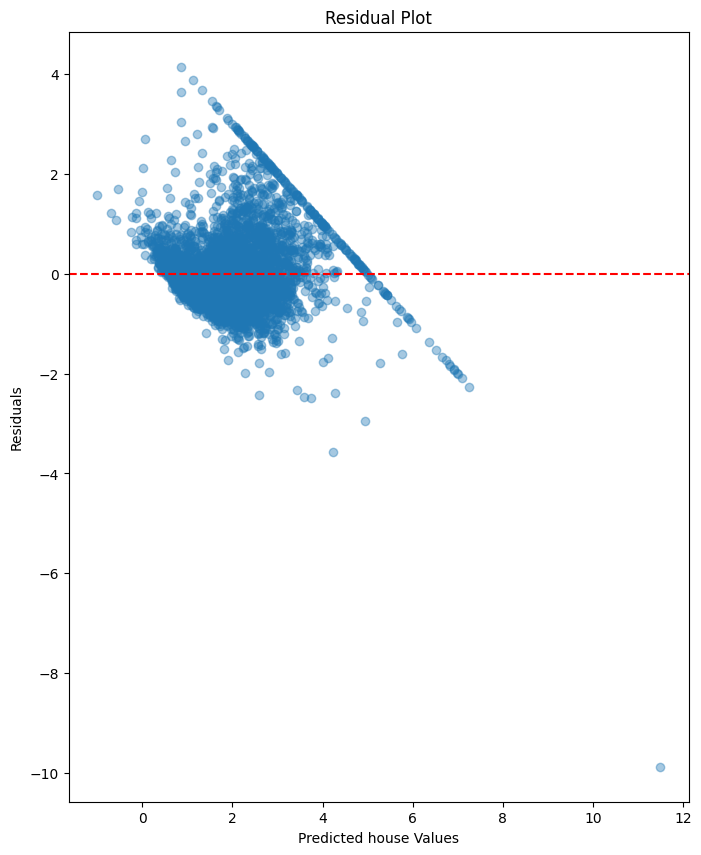

In [29]:
from matplotlib.lines import lineStyles
# visualize residuals

plt.figure(figsize=(8,10))
plt.scatter(y_pred,residuals,alpha= 0.4)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel("Predicted house Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()


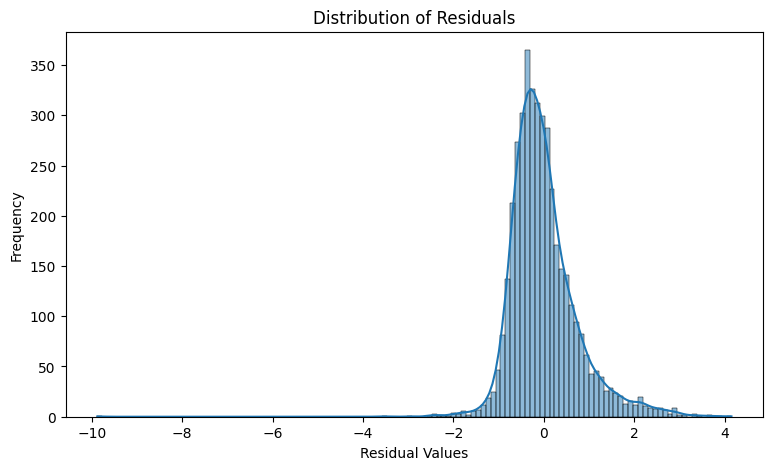

In [30]:
# checking the distribution results
plt.figure(figsize=(9, 5))

sns.histplot(residuals, kde=True)

plt.title("Distribution of Residuals")
plt.xlabel("Residual Values")
plt.ylabel("Frequency")

plt.show()

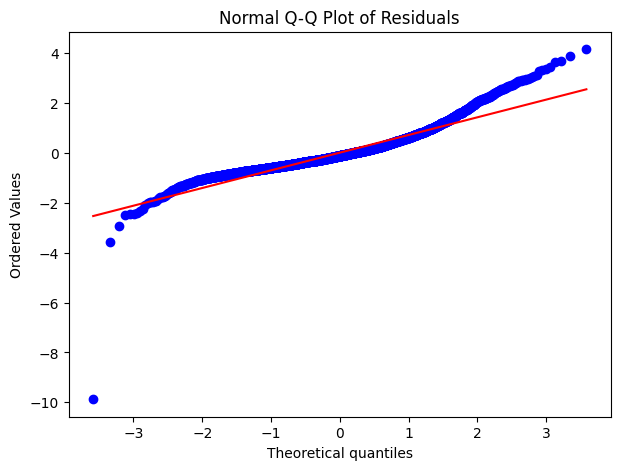

In [31]:
# identifying with the residual was normal
import scipy.stats as stats

plt.figure(figsize=(7, 5))

stats.probplot(residuals, dist="norm", plot=plt)

plt.title("Normal Q-Q Plot of Residuals")

plt.show()